In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path.home() / "Documents" / "airline-delay-reliability-analysis"

monthly_dir = project_root / "data" / "processed" / "monthly"
figures_dir = project_root / "figures"

parquet_files = sorted(
    monthly_dir.glob("flights_2025_*.parquet")
)

network_columns = [
    "FlightDate",
    "Marketing_Airline_Network",
    "Operating_Airline",
    "Tail_Number",
    "Flight_Number_Operating_Airline",
    "Origin",
    "Dest",
    "CRSDepTime",
    "DepTime",
    "DepDelayMinutes",
    "CRSArrTime",
    "ArrTime",
    "ArrDelayMinutes",
    "ArrDel15",
    "Cancelled",
    "Diverted",
    "LateAircraftDelay"
]

monthly_dfs = []

for file in parquet_files:
    month_df = pd.read_parquet(
        file,
        columns=network_columns,
        engine="pyarrow"
    )
    monthly_dfs.append(month_df)

network_df = pd.concat(
    monthly_dfs,
    ignore_index=True
)

memory_mb = (
    network_df.memory_usage(deep=True).sum()
    / 1024**2
)

print(f"Rows: {network_df.shape[0]:,}")
print(f"Columns: {network_df.shape[1]}")
print(f"Memory usage: {memory_mb:.2f} MB")
print(
    f"Date range: {network_df['FlightDate'].min()} "
    f"to {network_df['FlightDate'].max()}"
)

print()
print("Missing Tail_Number:")
print(network_df["Tail_Number"].isna().sum())

print()
print("Unique Tail Numbers:")
print(network_df["Tail_Number"].nunique())

Rows: 4,518,993
Columns: 17
Memory usage: 655.53 MB
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00

Missing Tail_Number:
11105

Unique Tail Numbers:
4551


In [2]:
rotation_df = network_df[
    network_df["Tail_Number"].notna()
].copy()

rotation_df["FlightDate"] = pd.to_datetime(
    rotation_df["FlightDate"]
)

crs_dep = (
    rotation_df["CRSDepTime"]
    .fillna(0)
    .astype(int)
)

dep_hour = crs_dep // 100
dep_minute = crs_dep % 100

next_day_mask = dep_hour == 24

dep_hour = dep_hour.where(~next_day_mask, 0)

rotation_df["scheduled_departure_ts"] = (
    rotation_df["FlightDate"]
    + pd.to_timedelta(dep_hour, unit="h")
    + pd.to_timedelta(dep_minute, unit="m")
    + pd.to_timedelta(next_day_mask.astype(int), unit="D")
)

rotation_df = rotation_df.sort_values(
    ["Tail_Number", "scheduled_departure_ts"]
).reset_index(drop=True)

print(f"Rows available for rotation analysis: {len(rotation_df):,}")
print(
    f"Missing scheduled timestamps: "
    f"{rotation_df['scheduled_departure_ts'].isna().sum():,}"
)
print(
    f"Unique tail numbers: "
    f"{rotation_df['Tail_Number'].nunique():,}"
)

rotation_df[
    [
        "Tail_Number",
        "FlightDate",
        "Origin",
        "Dest",
        "CRSDepTime",
        "scheduled_departure_ts"
    ]
].head(10)

Rows available for rotation analysis: 4,507,888
Missing scheduled timestamps: 0
Unique tail numbers: 4,551


,Tail_Number,FlightDate,Origin,Dest,CRSDepTime,scheduled_departure_ts
0,N10156,2025-01-01,LCH,IAH,730,2025-01-01 07:30:00
1,N10156,2025-01-01,IAH,HSV,1005,2025-01-01 10:05:00
2,N10156,2025-01-02,HSV,IAH,1630,2025-01-02 16:30:00
3,N10156,2025-01-02,IAH,LCH,2035,2025-01-02 20:35:00
4,N10156,2025-01-03,LCH,IAH,730,2025-01-03 07:30:00
5,N10156,2025-01-03,IAH,MFE,730,2025-01-03 07:30:00
6,N10156,2025-01-03,MFE,IAH,945,2025-01-03 09:45:00
7,N10156,2025-01-03,IAH,LRD,2015,2025-01-03 20:15:00
8,N10156,2025-01-04,LRD,IAH,930,2025-01-04 09:30:00
9,N10156,2025-01-04,IAH,LBB,1300,2025-01-04 13:00:00


In [3]:
tail_time_counts = (
    rotation_df
    .groupby(["Tail_Number", "scheduled_departure_ts"])
    .size()
    .reset_index(name="record_count")
)

conflicting_tail_times = tail_time_counts[
    tail_time_counts["record_count"] > 1
].copy()

print(
    f"Tail-time combinations with multiple records: "
    f"{len(conflicting_tail_times):,}"
)

print(
    f"Flights involved in these combinations: "
    f"{conflicting_tail_times['record_count'].sum():,}"
)

conflict_sample = rotation_df.merge(
    conflicting_tail_times[
        ["Tail_Number", "scheduled_departure_ts"]
    ],
    on=["Tail_Number", "scheduled_departure_ts"],
    how="inner"
)

conflict_sample[
    [
        "Tail_Number",
        "scheduled_departure_ts",
        "Marketing_Airline_Network",
        "Operating_Airline",
        "Flight_Number_Operating_Airline",
        "Origin",
        "Dest"
    ]
].head(30)

Tail-time combinations with multiple records: 1,035
Flights involved in these combinations: 2,070


,Tail_Number,scheduled_departure_ts,Marketing_Airline_Network,Operating_Airline,Flight_Number_Operating_Airline,Origin,Dest
0,N10156,2025-01-03 07:30:00,UA,C5,4330,LCH,IAH
1,N10156,2025-01-03 07:30:00,UA,C5,4226,IAH,MFE
2,N102DN,2025-07-28 06:05:00,DL,DL,2510,LGA,MSP
3,N102DN,2025-07-28 06:05:00,DL,DL,1745,DEN,DTW
4,N102HQ,2025-08-06 10:00:00,AA,YX,4539,PIT,ORD
5,N102HQ,2025-08-06 10:00:00,AA,YX,4583,ORD,RDU
6,N103DY,2025-08-01 06:00:00,DL,DL,404,ATL,LGA
7,N103DY,2025-08-01 06:00:00,DL,DL,651,ATL,DTW
8,N103SY,2025-01-20 17:50:00,UA,OO,5526,ORD,ATW
9,N103SY,2025-01-20 17:50:00,UA,OO,5606,CHO,ORD


In [4]:
rotation_df["tail_time_conflict"] = rotation_df.duplicated(
    subset=["Tail_Number", "scheduled_departure_ts"],
    keep=False
)

conflict_rows = rotation_df["tail_time_conflict"].sum()

print(f"Conflict rows: {conflict_rows:,}")
print(
    f"Conflict share: "
    f"{conflict_rows / len(rotation_df) * 100:.3f}%"
)

propagation_base = rotation_df[
    (~rotation_df["tail_time_conflict"])
    & (rotation_df["Cancelled"] == 0)
    & (rotation_df["Diverted"] == 0)
    & (rotation_df["ArrDel15"].notna())
].copy()

propagation_base = propagation_base.sort_values(
    ["Tail_Number", "scheduled_departure_ts"]
).reset_index(drop=True)

print()
print(f"Rows in clean propagation base: {len(propagation_base):,}")
print(
    f"Share of tail-number records retained: "
    f"{len(propagation_base) / len(rotation_df) * 100:.2f}%"
)

Conflict rows: 2,070
Conflict share: 0.046%

Rows in clean propagation base: 4,428,696
Share of tail-number records retained: 98.24%


In [5]:
propagation_base["previous_origin"] = (
    propagation_base
    .groupby("Tail_Number")["Origin"]
    .shift(1)
)

propagation_base["previous_dest"] = (
    propagation_base
    .groupby("Tail_Number")["Dest"]
    .shift(1)
)

propagation_base["previous_flight_date"] = (
    propagation_base
    .groupby("Tail_Number")["FlightDate"]
    .shift(1)
)

propagation_base["previous_arrival_delay"] = (
    propagation_base
    .groupby("Tail_Number")["ArrDelayMinutes"]
    .shift(1)
)

propagation_base["previous_arr_del15"] = (
    propagation_base
    .groupby("Tail_Number")["ArrDel15"]
    .shift(1)
)

propagation_base["previous_late_aircraft_delay"] = (
    propagation_base
    .groupby("Tail_Number")["LateAircraftDelay"]
    .shift(1)
)

propagation_base["previous_scheduled_departure_ts"] = (
    propagation_base
    .groupby("Tail_Number")["scheduled_departure_ts"]
    .shift(1)
)

propagation_base["date_gap_days"] = (
    propagation_base["FlightDate"]
    - propagation_base["previous_flight_date"]
).dt.days

propagation_base["valid_rotation_pair"] = (
    propagation_base["previous_dest"].eq(
        propagation_base["Origin"]
    )
    &
    propagation_base["date_gap_days"].between(0, 1)
    &
    propagation_base["previous_arr_del15"].notna()
)

rotation_pairs = propagation_base[
    propagation_base["valid_rotation_pair"]
].copy()

print(f"Valid consecutive flight pairs: {len(rotation_pairs):,}")

print(
    f"Share of propagation-base flights with a valid previous leg: "
    f"{len(rotation_pairs) / len(propagation_base) * 100:.2f}%"
)

print()
print("Previous flight delayed distribution:")
print(
    rotation_pairs["previous_arr_del15"]
    .value_counts()
    .sort_index()
)

rotation_pairs[
    [
        "Tail_Number",
        "previous_origin",
        "previous_dest",
        "Origin",
        "Dest",
        "previous_arrival_delay",
        "previous_arr_del15",
        "ArrDelayMinutes",
        "ArrDel15"
    ]
].head(15)

Valid consecutive flight pairs: 4,193,702
Share of propagation-base flights with a valid previous leg: 94.69%

Previous flight delayed distribution:
previous_arr_del15
0.0    3289852
1.0     903850
Name: count, dtype: int64


,Tail_Number,previous_origin,previous_dest,Origin,Dest,previous_arrival_delay,previous_arr_del15,ArrDelayMinutes,ArrDel15
1,N10156,LCH,IAH,IAH,HSV,0.0,0.0,0.0,0.0
2,N10156,IAH,HSV,HSV,IAH,0.0,0.0,3.0,0.0
3,N10156,HSV,IAH,IAH,LCH,3.0,0.0,0.0,0.0
5,N10156,MFE,IAH,IAH,LRD,473.0,1.0,9.0,0.0
6,N10156,IAH,LRD,LRD,IAH,9.0,0.0,0.0,0.0
7,N10156,LRD,IAH,IAH,LBB,0.0,0.0,0.0,0.0
8,N10156,IAH,LBB,LBB,IAH,0.0,0.0,0.0,0.0
9,N10156,LBB,IAH,IAH,SHV,0.0,0.0,0.0,0.0
10,N10156,IAH,SHV,SHV,IAH,0.0,0.0,0.0,0.0
11,N10156,SHV,IAH,IAH,XNA,0.0,0.0,0.0,0.0


In [6]:
propagation_summary = (
    rotation_pairs
    .groupby("previous_arr_del15")
    .agg(
        flight_pairs=("ArrDel15", "size"),
        current_delayed_flights=("ArrDel15", "sum"),
        avg_current_arrival_delay=("ArrDelayMinutes", "mean")
    )
)

propagation_summary["current_delay_rate_pct"] = (
    propagation_summary["current_delayed_flights"]
    / propagation_summary["flight_pairs"]
    * 100
)

propagation_summary["avg_current_arrival_delay"] = (
    propagation_summary["avg_current_arrival_delay"].round(2)
)

propagation_summary["current_delay_rate_pct"] = (
    propagation_summary["current_delay_rate_pct"].round(2)
)

propagation_summary.index = [
    "Previous Flight On Time",
    "Previous Flight Delayed"
]

propagation_summary

,flight_pairs,current_delayed_flights,avg_current_arrival_delay,current_delay_rate_pct
Previous Flight On Time,3289852,454815.0,9.37,13.82
Previous Flight Delayed,903850,437510.0,41.18,48.41


In [7]:
on_time_prev_rate = propagation_summary.loc[
    "Previous Flight On Time",
    "current_delay_rate_pct"
]

delayed_prev_rate = propagation_summary.loc[
    "Previous Flight Delayed",
    "current_delay_rate_pct"
]

propagation_rate = delayed_prev_rate

risk_difference = delayed_prev_rate - on_time_prev_rate

risk_ratio = delayed_prev_rate / on_time_prev_rate

print(f"Late Aircraft Propagation Rate: {propagation_rate:.2f}%")
print(f"Baseline next-flight delay rate: {on_time_prev_rate:.2f}%")
print(f"Risk difference: {risk_difference:.2f} percentage points")
print(f"Risk ratio: {risk_ratio:.2f}x")

Late Aircraft Propagation Rate: 48.41%
Baseline next-flight delay rate: 13.82%
Risk difference: 34.59 percentage points
Risk ratio: 3.50x


In [8]:
delay_bins = [
    0,
    15,
    30,
    60,
    120,
    np.inf
]

delay_labels = [
    "0-14 min",
    "15-29 min",
    "30-59 min",
    "60-119 min",
    "120+ min"
]

rotation_pairs["previous_delay_band"] = pd.cut(
    rotation_pairs["previous_arrival_delay"],
    bins=delay_bins,
    labels=delay_labels,
    right=False
)

dose_response = (
    rotation_pairs
    .groupby(
        "previous_delay_band",
        observed=True
    )
    .agg(
        flight_pairs=("ArrDel15", "size"),
        current_delayed_flights=("ArrDel15", "sum"),
        avg_current_arrival_delay=("ArrDelayMinutes", "mean")
    )
)

dose_response["current_delay_rate_pct"] = (
    dose_response["current_delayed_flights"]
    / dose_response["flight_pairs"]
    * 100
)

dose_response["current_delay_rate_pct"] = (
    dose_response["current_delay_rate_pct"].round(2)
)

dose_response["avg_current_arrival_delay"] = (
    dose_response["avg_current_arrival_delay"].round(2)
)

dose_response

,flight_pairs,current_delayed_flights,avg_current_arrival_delay,current_delay_rate_pct
previous_delay_band,,,,
0-14 min,3289852,454815.0,9.37,13.82
15-29 min,290805,90049.0,18.97,30.97
30-59 min,266786,135027.0,29.88,50.61
60-119 min,202636,124890.0,50.88,61.63
120+ min,143623,87544.0,93.46,60.95


In [9]:
airline_propagation = (
    rotation_pairs
    .groupby(
        [
            "Marketing_Airline_Network",
            "previous_arr_del15"
        ]
    )
    .agg(
        flight_pairs=("ArrDel15", "size"),
        current_delayed_flights=("ArrDel15", "sum")
    )
    .reset_index()
)

airline_propagation["current_delay_rate_pct"] = (
    airline_propagation["current_delayed_flights"]
    / airline_propagation["flight_pairs"]
    * 100
)

airline_propagation["previous_status"] = np.where(
    airline_propagation["previous_arr_del15"] == 1,
    "Previous Flight Delayed",
    "Previous Flight On Time"
)

airline_pivot = airline_propagation.pivot(
    index="Marketing_Airline_Network",
    columns="previous_status",
    values="current_delay_rate_pct"
)

airline_pivot["risk_difference_pp"] = (
    airline_pivot["Previous Flight Delayed"]
    - airline_pivot["Previous Flight On Time"]
)

airline_pivot["risk_ratio"] = (
    airline_pivot["Previous Flight Delayed"]
    / airline_pivot["Previous Flight On Time"]
)

airline_pivot = airline_pivot.round(2)

airline_pivot

previous_status,Previous Flight Delayed,Previous Flight On Time,risk_difference_pp,risk_ratio
Marketing_Airline_Network,,,,
AA,50.29,15.09,35.20,3.33
DL,49.71,11.62,38.09,4.28
UA,44.51,14.81,29.70,3.01


In [10]:
core_airports = [
    "ATL", "DFW", "DEN", "ORD",
    "CLT", "MIA", "PHX",
    "DTW", "MSP", "SLC",
    "JFK", "LGA",
    "IAH", "EWR", "SFO", "LAX"
]

airport_pairs = rotation_pairs[
    rotation_pairs["Origin"].isin(core_airports)
].copy()

airport_propagation = (
    airport_pairs
    .groupby(
        ["Origin", "previous_arr_del15"]
    )
    .agg(
        flight_pairs=("ArrDel15", "size"),
        current_delayed_flights=("ArrDel15", "sum")
    )
    .reset_index()
)

airport_propagation["current_delay_rate_pct"] = (
    airport_propagation["current_delayed_flights"]
    / airport_propagation["flight_pairs"]
    * 100
)

airport_propagation["previous_status"] = np.where(
    airport_propagation["previous_arr_del15"] == 1,
    "Previous Flight Delayed",
    "Previous Flight On Time"
)

airport_rate_pivot = airport_propagation.pivot(
    index="Origin",
    columns="previous_status",
    values="current_delay_rate_pct"
)

airport_count_pivot = airport_propagation.pivot(
    index="Origin",
    columns="previous_status",
    values="flight_pairs"
)

airport_rate_pivot["risk_difference_pp"] = (
    airport_rate_pivot["Previous Flight Delayed"]
    - airport_rate_pivot["Previous Flight On Time"]
)

airport_rate_pivot["risk_ratio"] = (
    airport_rate_pivot["Previous Flight Delayed"]
    / airport_rate_pivot["Previous Flight On Time"]
)

airport_rate_pivot["delayed_previous_pairs"] = (
    airport_count_pivot["Previous Flight Delayed"]
)

airport_rate_pivot = (
    airport_rate_pivot
    .round(2)
    .sort_values(
        "risk_difference_pp",
        ascending=False
    )
)

airport_rate_pivot

previous_status,Previous Flight Delayed,Previous Flight On Time,risk_difference_pp,risk_ratio,delayed_previous_pairs
Origin,,,,,
LGA,54.99,15.95,39.04,3.45,33005
ATL,54.42,15.82,38.59,3.44,49408
CLT,52.08,15.93,36.15,3.27,41497
DTW,50.78,14.86,35.92,3.42,21722
DEN,50.16,14.62,35.53,3.43,42849
JFK,49.03,14.42,34.61,3.40,15434
ORD,50.76,17.22,33.54,2.95,79357
DFW,52.82,20.12,32.71,2.63,67611
MSP,46.43,14.15,32.28,3.28,20799


In [11]:
airport_operational = (
    network_df[
        network_df["Origin"].isin(core_airports)
    ]
    .groupby("Origin")
    .agg(
        scheduled_departures=("Origin", "size"),
        completed_arrivals=("ArrDel15", "count"),
        delayed_arrivals=("ArrDel15", "sum"),
        late_aircraft_delay_minutes=("LateAircraftDelay", "sum")
    )
)

airport_operational["overall_delay_rate_pct"] = (
    airport_operational["delayed_arrivals"]
    / airport_operational["completed_arrivals"]
    * 100
)

airport_operational["late_aircraft_intensity"] = (
    airport_operational["late_aircraft_delay_minutes"]
    / airport_operational["completed_arrivals"]
    * 1000
)

priority_df = airport_rate_pivot.join(
    airport_operational[
        [
            "scheduled_departures",
            "overall_delay_rate_pct",
            "late_aircraft_intensity"
        ]
    ]
)

priority_df["propagation_priority_score"] = (
    priority_df["delayed_previous_pairs"]
    * priority_df["risk_difference_pp"]
    / 100
)

priority_df["overall_delay_rate_pct"] = (
    priority_df["overall_delay_rate_pct"].round(2)
)

priority_df["late_aircraft_intensity"] = (
    priority_df["late_aircraft_intensity"].round(0)
)

priority_df["propagation_priority_score"] = (
    priority_df["propagation_priority_score"].round(0)
)

priority_df = priority_df[
    [
        "scheduled_departures",
        "overall_delay_rate_pct",
        "Previous Flight On Time",
        "Previous Flight Delayed",
        "risk_difference_pp",
        "risk_ratio",
        "delayed_previous_pairs",
        "late_aircraft_intensity",
        "propagation_priority_score"
    ]
].sort_values(
    "propagation_priority_score",
    ascending=False
)

priority_df

,scheduled_departures,overall_delay_rate_pct,Previous Flight On Time,Previous Flight Delayed,risk_difference_pp,risk_ratio,delayed_previous_pairs,late_aircraft_intensity,propagation_priority_score
Origin,,,,,,,,,
ORD,338620,26.54,17.22,50.76,33.54,2.95,79357,8611.0,26616.0
DFW,298451,28.83,20.12,52.82,32.71,2.63,67611,9448.0,22116.0
ATL,300059,22.92,15.82,54.42,38.59,3.44,49408,3944.0,19067.0
DEN,200911,23.39,14.62,50.16,35.53,3.43,42849,6957.0,15224.0
CLT,233136,23.21,15.93,52.08,36.15,3.27,41497,7572.0,15001.0
LGA,141003,26.09,15.95,54.99,39.04,3.45,33005,8243.0,12885.0
IAH,157107,20.95,14.56,44.92,30.36,3.09,27411,6268.0,8322.0
DTW,122607,22.13,14.86,50.78,35.92,3.42,21722,3420.0,7803.0
EWR,113239,25.33,16.89,45.66,28.77,2.70,26936,9880.0,7749.0


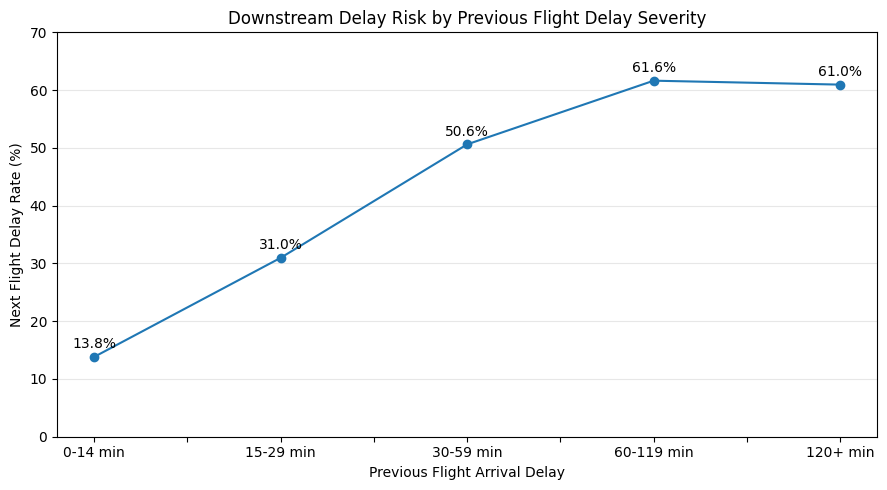

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\delay_propagation_dose_response.png


In [12]:
ax = dose_response["current_delay_rate_pct"].plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

ax.set_title("Downstream Delay Risk by Previous Flight Delay Severity")
ax.set_xlabel("Previous Flight Arrival Delay")
ax.set_ylabel("Next Flight Delay Rate (%)")
ax.set_ylim(0, 70)
ax.grid(axis="y", alpha=0.3)

for x, y in enumerate(dose_response["current_delay_rate_pct"]):
    ax.text(
        x,
        y + 1.5,
        f"{y:.1f}%",
        ha="center"
    )

plt.tight_layout()

output_path = figures_dir / "delay_propagation_dose_response.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

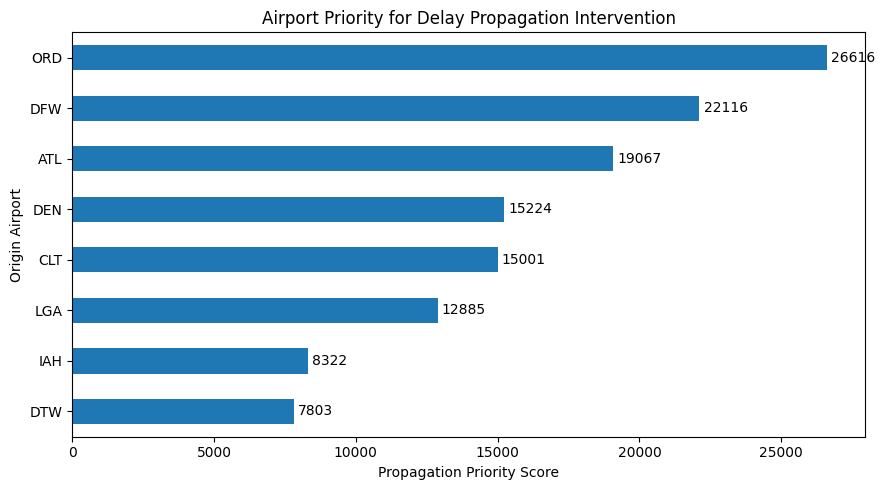

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\airport_propagation_priority.png


In [13]:
top_priority = (
    priority_df
    .head(8)
    .sort_values(
        "propagation_priority_score",
        ascending=True
    )
)

ax = top_priority["propagation_priority_score"].plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_title("Airport Priority for Delay Propagation Intervention")
ax.set_xlabel("Propagation Priority Score")
ax.set_ylabel("Origin Airport")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3
    )

plt.tight_layout()

output_path = figures_dir / "airport_propagation_priority.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

In [14]:
day4_findings = """# Day 4 - Network Reliability & Delay Propagation: Key Findings

## 1. Aircraft Rotation Sample

Aircraft tail numbers were used to reconstruct consecutive flight rotations.

- Total analytical flights: 4,518,993
- Flights missing Tail Number: 11,105
- Unique aircraft tail numbers: 4,551
- Tail-number/time conflicts represented only 0.046% of records
- 98.24% of tail-number records were retained after propagation data cleaning

A valid consecutive flight pair required the previous flight destination to match the current flight origin.

## 2. Overall Delay Propagation

The downstream delay rate differs substantially depending on the status of the previous flight.

- Previous flight on time: 13.82% next-flight delay rate
- Previous flight delayed >=15 minutes: 48.41% next-flight delay rate
- Risk difference: +34.59 percentage points
- Risk ratio: 3.50x

This provides strong evidence of a network delay propagation pattern.

These results describe an association and should not be interpreted as a causal estimate.

## 3. Upstream Delay Severity

Downstream delay risk increases sharply with the severity of the previous flight delay.

- 0-14 minutes: 13.82%
- 15-29 minutes: 30.97%
- 30-59 minutes: 50.61%
- 60-119 minutes: 61.63%
- 120+ minutes: 60.95%

The relationship rises strongly and then appears to plateau once upstream delay exceeds approximately one hour.

Although the delay probability plateaus, flights following 120+ minute upstream delays still record very high average downstream arrival delay severity.

## 4. Airline Propagation Differences

The airline networks exhibit different propagation patterns.

AA:
- Previous flight on time: 15.09%
- Previous flight delayed: 50.29%
- Risk difference: +35.20 percentage points
- Risk ratio: 3.33x

DL:
- Previous flight on time: 11.62%
- Previous flight delayed: 49.71%
- Risk difference: +38.09 percentage points
- Risk ratio: 4.28x

UA:
- Previous flight on time: 14.81%
- Previous flight delayed: 44.51%
- Risk difference: +29.70 percentage points
- Risk ratio: 3.01x

AA has the highest conditional downstream delay rate after an upstream delay, while DL shows the largest relative increase from its lower baseline delay risk.

## 5. Airport Propagation Differences

Propagation sensitivity differs materially across core airports.

Examples:

- LGA: 15.95% baseline vs 54.99% after previous delay
- ATL: 15.82% vs 54.42%
- CLT: 15.93% vs 52.08%
- DFW: 20.12% vs 52.82%
- ORD: 17.22% vs 50.76%

Some airports have high propagation sensitivity, while others have greater operational exposure because of higher flight volume.

## 6. Propagation Intervention Priority

A transparent prioritization metric was constructed as:

Propagation Priority Score
= Delayed Previous Flight Pairs
x Propagation Risk Difference

This score represents propagation exposure multiplied by downstream risk uplift.

It is a prioritization metric and not a causal estimate of additional delays.

Highest-priority airports:

1. ORD
2. DFW
3. ATL
4. DEN
5. CLT
6. LGA
7. IAH
8. DTW

ORD and DFW are particularly important because they combine large aircraft-rotation exposure with substantial propagation risk.

## Business Implication

Delay reduction should not focus only on individual delayed flights.

The results indicate that upstream disruptions can persist through aircraft rotations and amplify later in the operating day.

Potential intervention areas include:

- aircraft rotation recovery
- targeted schedule buffers
- faster turnaround recovery
- spare aircraft or crew capacity at high-priority hubs
- proactive intervention after severe upstream delays
- airport-specific recovery strategies

These strategies will be evaluated financially in the later intervention and scenario analysis stage.
"""

docs_dir = project_root / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)

findings_path = docs_dir / "day4_network_findings.md"

findings_path.write_text(
    day4_findings,
    encoding="utf-8"
)

print(f"Saved to: {findings_path}")

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\docs\day4_network_findings.md
